# Computational Performance Benchmarking

This notebook compares the computational performance of KNN,
Random Forest, and MLP for Wi-Fi-based indoor localization.

In addition to classification accuracy, inference latency,
throughput, memory usage, and model size are evaluated to
understand the computational requirements of each model.

All models are evaluated using the same dataset, preprocessing
steps, and previously selected hyperparameters. All benchmarking
experiments are performed on the CPU to maintain consistency.

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import time
import os
import gc
import platform
import psutil
import joblib
import threading

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

import torch
import torch.nn as nn

results_dir = Path("results/performance_benchmarking")
results_dir.mkdir(parents=True, exist_ok=True)

## 2. Experimental Environment

The hardware and software specifications are recorded because
inference time and memory usage depend on the computational
environment.

All three models are evaluated under the same CPU-based
environment.

In [2]:
import sklearn

torch.set_num_threads(1)

environment = {
    "Operating System": platform.platform(),
    "Processor": platform.processor(),
    "CPU Architecture": platform.machine(),
    "Physical CPU Cores": psutil.cpu_count(logical=False),
    "Logical CPU Cores": psutil.cpu_count(logical=True),
    "Available Logical CPUs": len(psutil.Process().cpu_affinity()),
    "System RAM (GB)": round(
        psutil.virtual_memory().total / (1024 ** 3), 2
    ),
    "Python Version": platform.python_version(),
    "Scikit-learn Version": sklearn.__version__,
    "PyTorch Version": torch.__version__,
    "PyTorch Threads": torch.get_num_threads(),
    "Inference Device": "CPU"
}

environment_df = pd.DataFrame(
    environment.items(),
    columns=["Specification", "Value"]
)

display(environment_df)

environment_df.to_csv(
    results_dir / "experimental_environment.csv",
    index=False
)

,Specification,Value
0,Operating System,Linux-6.8.0-1070-azure-x86_64-with-glibc2.39
1,Processor,x86_64
2,CPU Architecture,x86_64
3,Physical CPU Cores,1
4,Logical CPU Cores,2
5,Available Logical CPUs,2
6,System RAM (GB),7.76
7,Python Version,3.14.2
8,Scikit-learn Version,1.9.1
9,PyTorch Version,2.15.0+cu132


## 3. Dataset Preparation

The same cleaned datasets and preprocessing procedure used
in the original model implementation are used for performance
benchmarking.

In [3]:
train_path = "data_preparation/processed/train_cleaned.csv"
val_path = "data_preparation/processed/validation_cleaned.csv"

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)

wap_cols = [
    c for c in train_df.columns if c.startswith("WAP")
]

X_train_raw = train_df[wap_cols]
y_train_raw = train_df["LOCATION_CLASS"]

X_holdout_raw = val_df[wap_cols]
y_holdout = val_df["LOCATION_CLASS"]

X_train, X_test, y_train, y_test = train_test_split(
    X_train_raw,
    y_train_raw,
    test_size=0.20,
    random_state=42,
    stratify=y_train_raw
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_holdout_scaled = scaler.transform(X_holdout_raw)

print("Training split:", X_train_scaled.shape)
print("Internal validation:", X_test_scaled.shape)
print("Official holdout:", X_holdout_scaled.shape)

Training split: (15440, 520)
Internal validation: (3860, 520)
Official holdout: (1111, 520)


## 4. Model Setup

The previously selected hyperparameters are reused without
performing additional hyperparameter tuning. KNN and Random
Forest are fitted using the training split, while the saved
MLP weights are loaded.

In [4]:
knn_model = KNeighborsClassifier(
    n_neighbors=1,
    metric="manhattan",
    weights="uniform",
    n_jobs=1
)

knn_model.fit(X_train_scaled, y_train)

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    max_features="log2",
    min_samples_split=2,
    random_state=42,
    n_jobs=1
)

rf_model.fit(X_train_scaled, y_train)

print("KNN and Random Forest ready.")

KNN and Random Forest ready.


In [5]:
torch.manual_seed(42)

device = torch.device("cpu")

le = LabelEncoder()
le.fit(y_train)

class IndoorLocalizationMLP(nn.Module):
    def __init__(self, input_dim=520, num_classes=13,
                 dropout_rate=0.2):

        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.network(x)

mlp_model = IndoorLocalizationMLP().to(device)

mlp_model.load_state_dict(
    torch.load(
        "best_mlp_weights.pt",
        map_location=device,
        weights_only=True
    )
)

mlp_model.eval()

print("MLP ready.")

MLP ready.


### 4.1 Model Performance Verification

The classification accuracy of each model is verified before
benchmarking to ensure consistency with the original experiments.

In [6]:
def predict_mlp(X):

    X_tensor = torch.tensor(X, dtype=torch.float32)

    with torch.inference_mode():
        outputs = mlp_model(X_tensor)
        indices = outputs.argmax(dim=1).cpu().numpy()

    return le.inverse_transform(indices)


models = {
    "KNN": knn_model.predict,
    "Random Forest": rf_model.predict,
    "MLP": predict_mlp
}

accuracy_results = []

for name, predict in models.items():

    y_pred = predict(X_holdout_scaled)

    accuracy_results.append({
        "Model": name,
        "Accuracy (%)": accuracy_score(y_holdout, y_pred) * 100,
        "Macro F1": f1_score(y_holdout, y_pred, average="macro")
    })

accuracy_df = pd.DataFrame(accuracy_results)

display(accuracy_df.round(4))

,Model,Accuracy (%),Macro F1
0,KNN,84.3384,0.8209
1,Random Forest,91.0891,0.8969
2,MLP,89.2889,0.8876


## 5. Inference Latency

### 5.1 Single-Sample Inference

Single-sample inference latency measures the time required to
predict one building-floor location.

Each model is warmed up before timing to reduce the effect of
initialization overhead. Inference is then performed on the same
100 randomly selected holdout samples, with five repetitions.

Mean, median, standard deviation, and 95th percentile latency
are reported in milliseconds.

In [7]:
from threadpoolctl import threadpool_limits

def benchmark_single_sample(predict, X, repetitions=5):

    times = []

    with threadpool_limits(limits=1):

        # Warm-up runs
        for i in range(10):
            predict(X[i:i+1])

        # Repeated inference
        for _ in range(repetitions):

            for i in range(len(X)):

                sample = X[i:i+1]

                start = time.perf_counter()
                predict(sample)
                end = time.perf_counter()

                times.append((end - start) * 1000)

    return np.array(times)

In [8]:
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(X_holdout_scaled),
    size=100,
    replace=False
)

benchmark_samples = X_holdout_scaled[sample_indices]

single_latency_results = []
single_latency_raw = {}

for name, predict in models.items():

    print("Benchmarking:", name)

    times = benchmark_single_sample(
        predict,
        benchmark_samples,
        repetitions=5
    )

    single_latency_raw[name] = times

    single_latency_results.append({
        "Model": name,
        "Number of Runs": len(times),
        "Mean Latency (ms)": np.mean(times),
        "Median Latency (ms)": np.median(times),
        "Std Dev (ms)": np.std(times),
        "Min Latency (ms)": np.min(times),
        "Max Latency (ms)": np.max(times),
        "95th Percentile (ms)": np.percentile(times, 95)
    })

single_latency_df = pd.DataFrame(single_latency_results)

display(single_latency_df.round(4))

Benchmarking: KNN
Benchmarking: Random Forest
Benchmarking: MLP


,Model,Number of Runs,Mean Latency (ms),Median Latency (ms),Std Dev (ms),Min Latency (ms),Max Latency (ms),95th Percentile (ms)
0,KNN,500,9.8737,8.5695,4.7897,7.8531,57.5498,17.4737
1,Random Forest,500,33.4116,28.4765,14.1888,24.1135,141.9935,61.3583
2,MLP,500,0.7342,0.6504,0.3667,0.3920,3.4777,1.3558


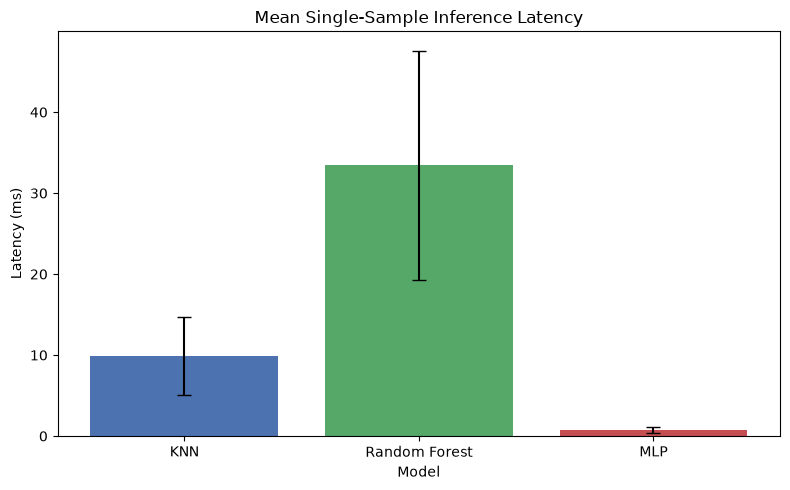

In [9]:
plt.figure(figsize=(8, 5))

plt.bar(
    single_latency_df["Model"],
    single_latency_df["Mean Latency (ms)"],
    yerr=single_latency_df["Std Dev (ms)"],
    capsize=5,
    color=["#4C72B0", "#55A868", "#C44E52"]
)

plt.title("Mean Single-Sample Inference Latency")
plt.xlabel("Model")
plt.ylabel("Latency (ms)")
plt.tight_layout()

plt.savefig(
    results_dir / "single_sample_latency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5.2 Batch Inference

Batch inference latency measures the time required to predict
all 1,111 samples in the official holdout dataset.

Each model is evaluated over 20 repeated runs after three
warm-up runs. Throughput is also calculated to measure the
number of samples that can be processed per second.

In [10]:
def benchmark_batch(predict, X, repetitions=20):

    times = []

    with threadpool_limits(limits=1):

        # Warm-up runs
        for _ in range(3):
            predict(X)

        # Repeated batch inference
        for _ in range(repetitions):

            start = time.perf_counter()
            predict(X)
            end = time.perf_counter()

            times.append((end - start) * 1000)

    return np.array(times)

In [11]:
batch_latency_results = []
batch_latency_raw = {}

for name, predict in models.items():

    print("Benchmarking:", name)

    times = benchmark_batch(
        predict,
        X_holdout_scaled,
        repetitions=20
    )

    batch_latency_raw[name] = times

    mean_latency = np.mean(times)

    throughput = len(X_holdout_scaled) / (mean_latency / 1000)

    batch_latency_results.append({
        "Model": name,
        "Batch Size": len(X_holdout_scaled),
        "Number of Runs": len(times),
        "Mean Batch Latency (ms)": mean_latency,
        "Median Batch Latency (ms)": np.median(times),
        "Std Dev (ms)": np.std(times),
        "95th Percentile (ms)": np.percentile(times, 95),
        "Time Per Sample (ms)": mean_latency / len(X_holdout_scaled),
        "Throughput (samples/sec)": throughput
    })

batch_latency_df = pd.DataFrame(batch_latency_results)

display(batch_latency_df.round(4))

Benchmarking: KNN
Benchmarking: Random Forest
Benchmarking: MLP


,Model,Batch Size,Number of Runs,Mean Batch Latency (ms),Median Batch Latency (ms),Std Dev (ms),95th Percentile (ms),Time Per Sample (ms),Throughput (samples/sec)
0,KNN,1111,20,8744.4941,8710.3713,239.3778,9162.7880,7.8708,127.0514
1,Random Forest,1111,20,99.0557,88.3405,25.6061,165.1674,0.0892,11215.9135
2,MLP,1111,20,13.6222,12.6068,1.6607,16.4408,0.0123,81557.8243


### 5.3 Latency and Throughput Comparison

Batch latency and throughput are compared to understand how
efficiently each model processes multiple Wi-Fi fingerprints.
Lower latency and higher throughput indicate better
computational performance.

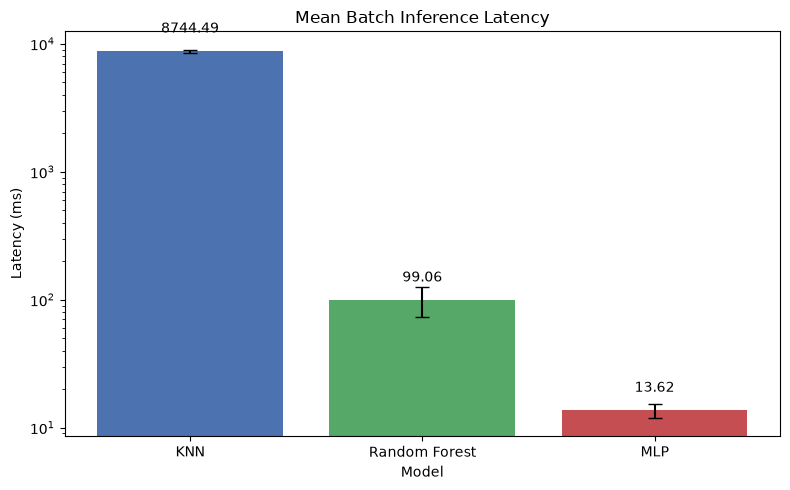

In [15]:
plt.figure(figsize=(8, 5))

plt.bar(
    batch_latency_df["Model"],
    batch_latency_df["Mean Batch Latency (ms)"],
    yerr=batch_latency_df["Std Dev (ms)"],
    capsize=5,
    color=["#4C72B0", "#55A868", "#C44E52"]
)

plt.title("Mean Batch Inference Latency")
plt.xlabel("Model")
plt.ylabel("Latency (ms)")
plt.yscale("log")

for i, value in enumerate(
    batch_latency_df["Mean Batch Latency (ms)"]
):
    plt.text(
        i, value * 1.4,
        f"{value:.2f}",
        ha="center"
    )
plt.tight_layout()

plt.savefig(
    results_dir / "batch_inference_latency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

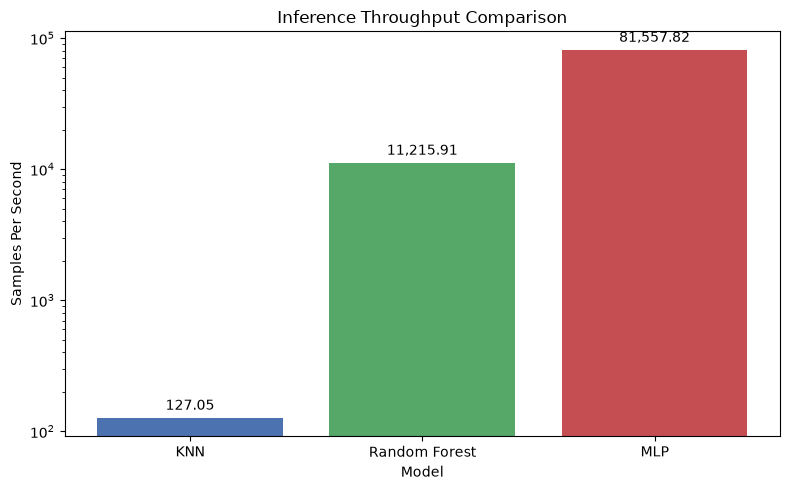

In [16]:
plt.figure(figsize=(8, 5))

plt.bar(
    batch_latency_df["Model"],
    batch_latency_df["Throughput (samples/sec)"],
    color=["#4C72B0", "#55A868", "#C44E52"]
)

plt.title("Inference Throughput Comparison")
plt.xlabel("Model")
plt.ylabel("Samples Per Second")
plt.yscale("log")

for i, value in enumerate(
    batch_latency_df["Throughput (samples/sec)"]
):
    plt.text(
        i, value * 1.15,
        f"{value:,.2f}",
        ha="center"
    )
plt.tight_layout()

plt.savefig(
    results_dir / "throughput_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
accuracy_df.to_csv(
    results_dir / "model_accuracy.csv",
    index=False
)

single_latency_df.to_csv(
    results_dir / "single_sample_latency.csv",
    index=False
)

batch_latency_df.to_csv(
    results_dir / "batch_inference_latency.csv",
    index=False
)

pd.DataFrame(single_latency_raw).to_csv(
    results_dir / "single_latency_raw.csv",
    index=False
)

pd.DataFrame(batch_latency_raw).to_csv(
    results_dir / "batch_latency_raw.csv",
    index=False
)

print("Latency benchmarking results saved successfully.")

Latency benchmarking results saved successfully.


### 5.4 Observations

MLP had the lowest single-sample inference latency of 0.7342 ms,
followed by KNN at 9.8737 ms and Random Forest at 33.4116 ms.

For batch inference, MLP processed all 1,111 holdout samples
in approximately 13.62 ms, while Random Forest took 99.06 ms
and KNN took 8,744.49 ms.

KNN had the highest batch inference time, which can be explained
by the need to compare incoming samples against the stored
training observations.

Random Forest achieved the highest classification accuracy
of 91.09%. However, MLP achieved an accuracy of 89.29% while
being approximately 45.5 times faster for single-sample
predictions and 7.27 times faster for batch predictions.

MLP also had the lowest standard deviation in single-sample
inference latency, indicating more consistent prediction
times during the experiments.

Overall, these results suggest that MLP may be more suitable
for real-time indoor localization applications where both
accuracy and prediction speed are important.

In [17]:
def measure_peak_memory(predict, X):

    process = psutil.Process(os.getpid())

    gc.collect()

    baseline = process.memory_info().rss
    peak = [baseline]

    stop_event = threading.Event()
    ready_event = threading.Event()

    def monitor_memory():

        ready_event.set()

        while not stop_event.is_set():

            current_memory = process.memory_info().rss
            peak[0] = max(peak[0], current_memory)

            stop_event.wait(0.001)

    monitor = threading.Thread(target=monitor_memory)

    monitor.start()
    ready_event.wait()

    try:

        predict(X)

        peak[0] = max(
            peak[0],
            process.memory_info().rss
        )

    finally:

        stop_event.set()
        monitor.join()

    return {
        "Baseline Memory (MB)": baseline / (1024 ** 2),
        "Peak Memory (MB)": peak[0] / (1024 ** 2),
        "Additional Memory (MB)": (peak[0] - baseline) / (1024 ** 2)
    }

In [18]:
memory_results = []

with threadpool_limits(limits=1):

    for name, predict in models.items():

        print("Measuring memory:", name)

        # Warm-up
        predict(X_holdout_scaled)

        for run in range(5):

            measurements = measure_peak_memory(
                predict,
                X_holdout_scaled
            )

            memory_results.append({
                "Model": name,
                "Run": run + 1,
                **measurements
            })

memory_raw_df = pd.DataFrame(memory_results)

display(memory_raw_df.round(4))

Measuring memory: KNN
Measuring memory: Random Forest
Measuring memory: MLP


,Model,Run,Baseline Memory (MB),Peak Memory (MB),Additional Memory (MB)
0,KNN,1,1178.0977,1182.4180,4.3203
1,KNN,2,1182.4141,1182.4180,0.0039
2,KNN,3,1182.4141,1182.4180,0.0039
3,KNN,4,1182.4141,1182.4180,0.0039
4,KNN,5,1182.4141,1182.4180,0.0039
5,Random Forest,1,1182.4141,1182.4180,0.0039
6,Random Forest,2,1182.4141,1182.4180,0.0039
7,Random Forest,3,1182.4141,1182.4180,0.0039
8,Random Forest,4,1182.4141,1182.4180,0.0039
9,Random Forest,5,1182.4141,1182.4180,0.0039


In [19]:
memory_df = memory_raw_df.groupby(
    "Model", sort=False
).agg(
    Mean_Baseline_MB=("Baseline Memory (MB)", "mean"),
    Mean_Peak_MB=("Peak Memory (MB)", "mean"),
    Maximum_Peak_MB=("Peak Memory (MB)", "max"),
    Mean_Additional_MB=("Additional Memory (MB)", "mean"),
    Maximum_Additional_MB=("Additional Memory (MB)", "max"),
    Std_Additional_MB=("Additional Memory (MB)", "std")
).reset_index()

display(memory_df.round(4))

,Model,Mean_Baseline_MB,Mean_Peak_MB,Maximum_Peak_MB,Mean_Additional_MB,Maximum_Additional_MB,Std_Additional_MB
0,KNN,1181.5508,1182.4180,1182.4180,0.8672,4.3203,1.9304
1,Random Forest,1182.4141,1182.4180,1182.4180,0.0039,0.0039,0.0000
2,MLP,1184.5156,1184.5195,1184.5195,0.0039,0.0039,0.0000


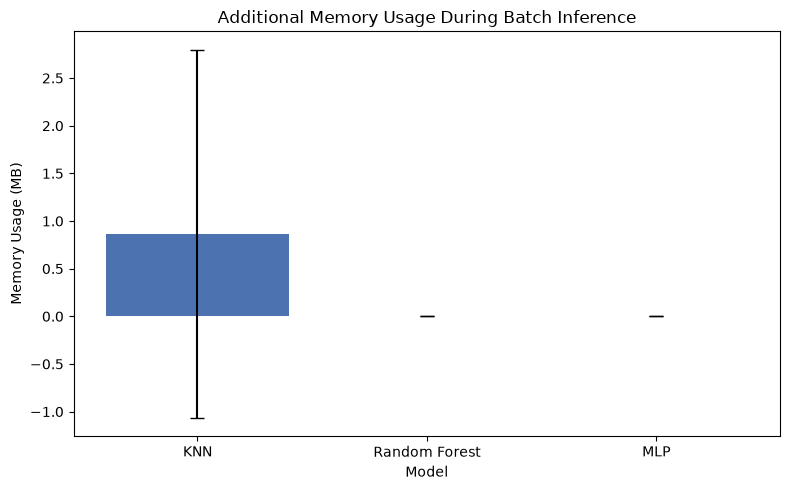

In [20]:
plt.figure(figsize=(8, 5))

plt.bar(
    memory_df["Model"],
    memory_df["Mean_Additional_MB"],
    yerr=memory_df["Std_Additional_MB"],
    capsize=5,
    color=["#4C72B0", "#55A868", "#C44E52"]
)

plt.title("Additional Memory Usage During Batch Inference")
plt.xlabel("Model")
plt.ylabel("Memory Usage (MB)")
plt.tight_layout()

plt.savefig(
    results_dir / "memory_usage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Model Size Comparison

The storage requirements of the three trained models are
compared by measuring their serialized file sizes.

KNN and Random Forest are serialized using joblib without
compression, while the MLP is evaluated using its saved
PyTorch state dictionary.

Model size is particularly relevant when deploying a model
on devices with limited storage capacity.

In [21]:
import tempfile

model_size_results = []

with tempfile.TemporaryDirectory() as temp_dir:

    temp_dir = Path(temp_dir)

    knn_path = temp_dir / "knn_model.joblib"
    rf_path = temp_dir / "rf_model.joblib"
    mlp_path = temp_dir / "mlp_model.pt"

    joblib.dump(knn_model, knn_path, compress=0)
    joblib.dump(rf_model, rf_path, compress=0)
    torch.save(mlp_model.state_dict(), mlp_path)

    model_files = {
        "KNN": knn_path,
        "Random Forest": rf_path,
        "MLP": mlp_path
    }

    for name, path in model_files.items():

        size_bytes = path.stat().st_size

        model_size_results.append({
            "Model": name,
            "Size (Bytes)": size_bytes,
            "Size (MB)": size_bytes / (1024 ** 2)
        })

model_size_df = pd.DataFrame(model_size_results)

display(model_size_df.round(4))

,Model,Size (Bytes),Size (MB)
0,KNN,64354980,61.3737
1,Random Forest,158145745,150.8195
2,MLP,1752792,1.6716


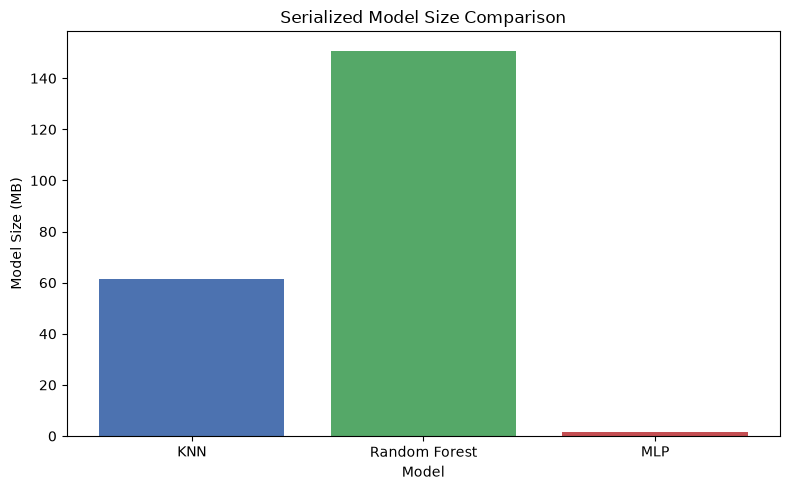

In [22]:
plt.figure(figsize=(8, 5))

plt.bar(
    model_size_df["Model"],
    model_size_df["Size (MB)"],
    color=["#4C72B0", "#55A868", "#C44E52"]
)

plt.title("Serialized Model Size Comparison")
plt.xlabel("Model")
plt.ylabel("Model Size (MB)")
plt.tight_layout()

plt.savefig(
    results_dir / "model_size_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
memory_raw_df.to_csv(
    results_dir / "memory_raw.csv",
    index=False
)

memory_df.to_csv(
    results_dir / "memory_summary.csv",
    index=False
)

model_size_df.to_csv(
    results_dir / "model_size.csv",
    index=False
)

print("Memory and model size results saved successfully.")

Memory and model size results saved successfully.


## 8. Overall Performance Comparison

Classification accuracy and computational performance are
combined to evaluate the trade-offs between predictive
performance, inference speed, memory usage, and storage
requirements.

In [24]:
final_benchmark_df = accuracy_df.merge(
    single_latency_df[
        ["Model", "Mean Latency (ms)", "95th Percentile (ms)"]
    ],
    on="Model"
)

final_benchmark_df = final_benchmark_df.merge(
    batch_latency_df[
        [
            "Model",
            "Mean Batch Latency (ms)",
            "Throughput (samples/sec)"
        ]
    ],
    on="Model"
)

final_benchmark_df = final_benchmark_df.merge(
    memory_df[
        ["Model", "Mean_Additional_MB", "Maximum_Additional_MB"]
    ],
    on="Model"
)

final_benchmark_df = final_benchmark_df.merge(
    model_size_df[
        ["Model", "Size (MB)"]
    ],
    on="Model"
)

display(final_benchmark_df.round(4))

final_benchmark_df.to_csv(
    results_dir / "final_benchmark_summary.csv",
    index=False
)

,Model,Accuracy (%),Macro F1,Mean Latency (ms),95th Percentile (ms),Mean Batch Latency (ms),Throughput (samples/sec),Mean_Additional_MB,Maximum_Additional_MB,Size (MB)
0,KNN,84.3384,0.8209,9.8737,17.4737,8744.4941,127.0514,0.8672,4.3203,61.3737
1,Random Forest,91.0891,0.8969,33.4116,61.3583,99.0557,11215.9135,0.0039,0.0039,150.8195
2,MLP,89.2889,0.8876,0.7342,1.3558,13.6222,81557.8243,0.0039,0.0039,1.6716


### 6.1 Isolated Process Memory Measurement

The initial memory experiment measured additional memory usage
within a shared notebook process. Since all three models were
already loaded, these measurements did not represent the
individual memory requirements of each model.

An additional experiment is performed using separate Python
processes to measure memory usage before model loading,
after model loading, and during batch inference.

In [25]:
import subprocess
import sys
import json
import tempfile

memory_script = """
import sys
import json
import os
import psutil
import joblib
import numpy as np
import threading
import gc
import resource

from threadpoolctl import threadpool_limits

model_name = sys.argv[1]
model_path = sys.argv[2]
data_path = sys.argv[3]

if model_name == "MLP":
    import torch
    import torch.nn as nn

    torch.set_num_threads(1)

    class IndoorLocalizationMLP(nn.Module):

        def __init__(self):
            super().__init__()

            self.network = nn.Sequential(
                nn.Linear(520, 512),
                nn.BatchNorm1d(512),
                nn.ReLU(),
                nn.Dropout(0.2),

                nn.Linear(512, 256),
                nn.BatchNorm1d(256),
                nn.ReLU(),
                nn.Dropout(0.2),

                nn.Linear(256, 128),
                nn.BatchNorm1d(128),
                nn.ReLU(),
                nn.Dropout(0.2),

                nn.Linear(128, 13)
            )

        def forward(self, x):
            return self.network(x)

else:
    import sklearn
    import sklearn.neighbors
    import sklearn.ensemble

process = psutil.Process(os.getpid())

X = np.load(data_path)

gc.collect()
baseline = process.memory_info().rss

if model_name == "MLP":

    model = IndoorLocalizationMLP()

    model.load_state_dict(
        torch.load(
            model_path,
            map_location="cpu",
            weights_only=True
        )
    )

    model.eval()

else:
    model = joblib.load(model_path)

gc.collect()

loaded = process.memory_info().rss

peak = [loaded]
stop = threading.Event()
ready = threading.Event()

def monitor():

    ready.set()

    while not stop.is_set():

        peak[0] = max(
            peak[0],
            process.memory_info().rss
        )

        stop.wait(0.001)

with threadpool_limits(limits=1):

    worker = threading.Thread(target=monitor)
    worker.start()
    ready.wait()

    try:

        if model_name == "MLP":

            with torch.inference_mode():

                output = model(
                    torch.tensor(X, dtype=torch.float32)
                )

                prediction = output.argmax(dim=1).numpy()

        else:
            prediction = model.predict(X)

        peak[0] = max(
            peak[0],
            process.memory_info().rss
        )

    finally:
        stop.set()
        worker.join()

mb = 1024 ** 2

print(json.dumps({
    "Model": model_name,
    "Baseline RSS (MiB)": baseline / mb,
    "Loaded RSS (MiB)": loaded / mb,
    "Model Loading Increase (MiB)": (loaded - baseline) / mb,
    "Peak Inference RSS (MiB)": peak[0] / mb,
    "Additional Inference RSS (MiB)": (peak[0] - loaded) / mb,
    "Process Peak RSS (MiB)":
        resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024
}))
"""

In [26]:
isolated_results = []

with tempfile.TemporaryDirectory() as temp:

    temp = Path(temp)

    script_path = temp / "memory_benchmark.py"
    script_path.write_text(memory_script)

    data_path = temp / "holdout.npy"
    np.save(data_path, X_holdout_scaled)

    knn_path = temp / "knn.joblib"
    rf_path = temp / "rf.joblib"
    mlp_path = temp / "mlp.pt"

    joblib.dump(knn_model, knn_path, compress=0)
    joblib.dump(rf_model, rf_path, compress=0)
    torch.save(mlp_model.state_dict(), mlp_path)

    model_paths = {
        "KNN": knn_path,
        "Random Forest": rf_path,
        "MLP": mlp_path
    }

    for name, path in model_paths.items():

        for run in range(3):

            print(name, "- Run", run + 1)

            output = subprocess.check_output(
                [
                    sys.executable,
                    str(script_path),
                    name,
                    str(path),
                    str(data_path)
                ],
                text=True
            )

            result = json.loads(output.strip())

            result["Run"] = run + 1

            isolated_results.append(result)

isolated_memory_raw_df = pd.DataFrame(isolated_results)

display(isolated_memory_raw_df.round(4))

KNN - Run 1
KNN - Run 2
KNN - Run 3
Random Forest - Run 1
Random Forest - Run 2
Random Forest - Run 3
MLP - Run 1
MLP - Run 2
MLP - Run 3


,Model,Baseline RSS (MiB),Loaded RSS (MiB),Model Loading Increase (MiB),Peak Inference RSS (MiB),Additional Inference RSS (MiB),Process Peak RSS (MiB),Run
0,KNN,164.3320,225.9414,61.6094,231.3281,5.3867,1277.6445,1
1,KNN,165.1133,226.7227,61.6094,232.0625,5.3398,1277.6445,2
2,KNN,165.2148,226.8242,61.6094,232.0586,5.2344,1277.6445,3
3,Random Forest,164.8047,468.3242,303.5195,470.6758,2.3516,1277.6445,1
4,Random Forest,164.9844,468.5508,303.5664,470.8398,2.2891,1277.6445,2
5,Random Forest,165.1484,468.6992,303.5508,470.9883,2.2891,1277.6445,3
6,MLP,478.9336,477.4883,-1.4453,486.5508,9.0625,1277.6445,1
7,MLP,536.9258,543.1094,6.1836,553.3008,10.1914,1277.6445,2
8,MLP,491.4570,497.7852,6.3281,507.1406,9.3555,1277.6445,3


In [27]:
isolated_memory_df = isolated_memory_raw_df.groupby(
    "Model", sort=False
).agg(
    Mean_Baseline_RSS=("Baseline RSS (MiB)", "mean"),

    Mean_Model_Loading_Increase=(
        "Model Loading Increase (MiB)", "mean"
    ),

    Mean_Loaded_RSS=("Loaded RSS (MiB)", "mean"),

    Mean_Peak_Inference_RSS=(
        "Peak Inference RSS (MiB)", "mean"
    ),

    Mean_Additional_Inference_RSS=(
        "Additional Inference RSS (MiB)", "mean"
    ),

    Maximum_Process_Peak_RSS=(
        "Process Peak RSS (MiB)", "max"
    )

).reset_index()

display(isolated_memory_df.round(4))

isolated_memory_raw_df.to_csv(
    results_dir / "isolated_memory_raw.csv",
    index=False
)

isolated_memory_df.to_csv(
    results_dir / "isolated_memory_summary.csv",
    index=False
)

,Model,Mean_Baseline_RSS,Mean_Model_Loading_Increase,Mean_Loaded_RSS,Mean_Peak_Inference_RSS,Mean_Additional_Inference_RSS,Maximum_Process_Peak_RSS
0,KNN,164.8867,61.6094,226.4961,231.8164,5.3203,1277.6445
1,Random Forest,164.9792,303.5456,468.5247,470.8346,2.3099,1277.6445
2,MLP,502.4388,3.6888,506.1276,515.6641,9.5365,1277.6445


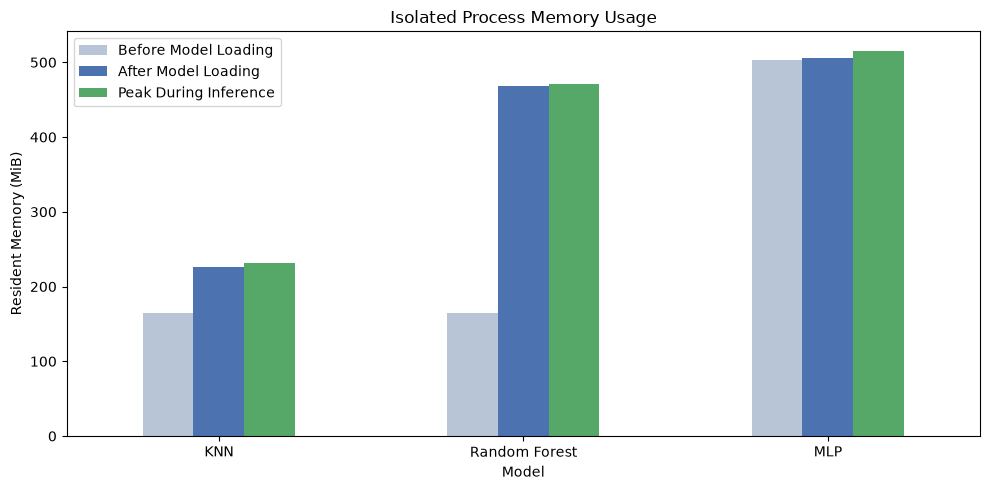

In [28]:
isolated_memory_df.set_index("Model")[
    [
        "Mean_Baseline_RSS",
        "Mean_Loaded_RSS",
        "Mean_Peak_Inference_RSS"
    ]
].plot(
    kind="bar",
    figsize=(10, 5),
    color=["#B8C5D6", "#4C72B0", "#55A868"]
)

plt.title("Isolated Process Memory Usage")
plt.xlabel("Model")
plt.ylabel("Resident Memory (MiB)")
plt.xticks(rotation=0)

plt.legend([
    "Before Model Loading",
    "After Model Loading",
    "Peak During Inference"
])

plt.tight_layout()

plt.savefig(
    results_dir / "isolated_memory_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 8.1 Accuracy and Computational Efficiency

The relationship between classification accuracy and inference
throughput is examined to determine whether improvements in
computational efficiency require a substantial reduction in
classification performance.

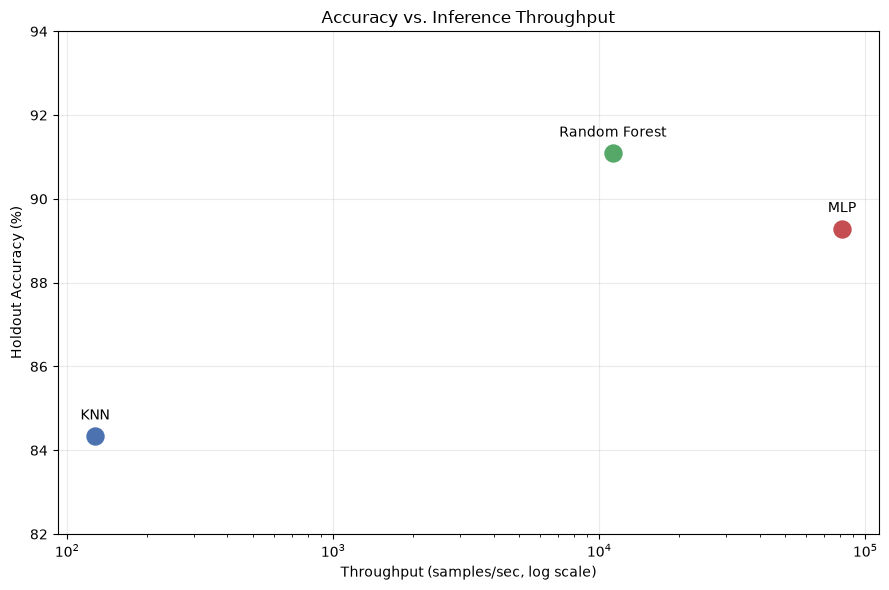

In [29]:
plt.figure(figsize=(9, 6))

colors = {
    "KNN": "#4C72B0",
    "Random Forest": "#55A868",
    "MLP": "#C44E52"
}

for _, row in final_benchmark_df.iterrows():

    plt.scatter(
        row["Throughput (samples/sec)"],
        row["Accuracy (%)"],
        s=150,
        color=colors[row["Model"]],
        label=row["Model"]
    )

    plt.annotate(
        row["Model"],
        (
            row["Throughput (samples/sec)"],
            row["Accuracy (%)"]
        ),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center"
    )

plt.xscale("log")
plt.ylim(82, 94)

plt.title("Accuracy vs. Inference Throughput")
plt.xlabel("Throughput (samples/sec, log scale)")
plt.ylabel("Holdout Accuracy (%)")
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    results_dir / "accuracy_vs_throughput.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

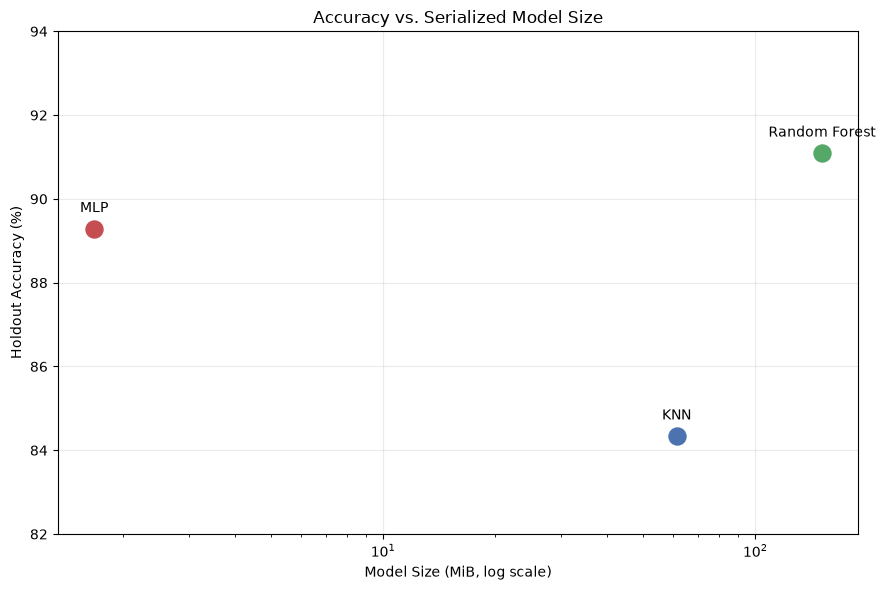

In [30]:
plt.figure(figsize=(9, 6))

for _, row in final_benchmark_df.iterrows():

    plt.scatter(
        row["Size (MB)"],
        row["Accuracy (%)"],
        s=150,
        color=colors[row["Model"]]
    )

    plt.annotate(
        row["Model"],
        (row["Size (MB)"], row["Accuracy (%)"]),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center"
    )

plt.xscale("log")
plt.ylim(82, 94)

plt.title("Accuracy vs. Serialized Model Size")
plt.xlabel("Model Size (MiB, log scale)")
plt.ylabel("Holdout Accuracy (%)")
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    results_dir / "accuracy_vs_model_size.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Memory Usage Observations

KNN had the lowest total peak inference memory of approximately
231.82 MiB, followed by Random Forest at 470.83 MiB and MLP
at 515.66 MiB.

Random Forest had the largest increase in memory after loading
the trained model, requiring approximately 303.55 MiB.
KNN required 61.61 MiB, while MLP required only 3.69 MiB.

Although MLP had the smallest serialized model size and model
loading increase, it had a higher baseline memory usage.
This is likely due in part to the PyTorch library and its
runtime dependencies.

The initial shared-process memory experiment showed very small
additional memory allocations because the models were already
loaded and previously allocated memory could be reused.

The isolated process experiment provides a more useful
comparison by separating baseline memory, model loading memory,
and additional inference memory.

These results also show that serialized model size and total
runtime memory usage are different measurements.

## 9. Final Benchmarking Summary

The final comparison combines classification performance,
inference latency, throughput, serialized model size, and
isolated process memory measurements.

In [31]:
final_summary_df = final_benchmark_df.drop(
    columns=[
        "Mean_Additional_MB",
        "Maximum_Additional_MB"
    ]
).copy()

final_summary_df = final_summary_df.rename(
    columns={"Size (MB)": "Model Size (MiB)"}
)

final_summary_df = final_summary_df.merge(
    isolated_memory_df[
        [
            "Model",
            "Mean_Baseline_RSS",
            "Mean_Model_Loading_Increase",
            "Mean_Loaded_RSS",
            "Mean_Peak_Inference_RSS",
            "Mean_Additional_Inference_RSS"
        ]
    ],
    on="Model"
)

display(final_summary_df.round(4))

final_summary_df.to_csv(
    results_dir / "final_benchmark_summary.csv",
    index=False
)

,Model,Accuracy (%),Macro F1,Mean Latency (ms),95th Percentile (ms),Mean Batch Latency (ms),Throughput (samples/sec),Model Size (MiB),Mean_Baseline_RSS,Mean_Model_Loading_Increase,Mean_Loaded_RSS,Mean_Peak_Inference_RSS,Mean_Additional_Inference_RSS
0,KNN,84.3384,0.8209,9.8737,17.4737,8744.4941,127.0514,61.3737,164.8867,61.6094,226.4961,231.8164,5.3203
1,Random Forest,91.0891,0.8969,33.4116,61.3583,99.0557,11215.9135,150.8195,164.9792,303.5456,468.5247,470.8346,2.3099
2,MLP,89.2889,0.8876,0.7342,1.3558,13.6222,81557.8243,1.6716,502.4388,3.6888,506.1276,515.6641,9.5365


In [32]:
comparison = final_summary_df.set_index("Model")

rf = comparison.loc["Random Forest"]
mlp = comparison.loc["MLP"]
knn = comparison.loc["KNN"]

relative_results = {
    "MLP single-sample speedup over RF":
        rf["Mean Latency (ms)"] / mlp["Mean Latency (ms)"],

    "MLP batch speedup over RF":
        rf["Mean Batch Latency (ms)"] /
        mlp["Mean Batch Latency (ms)"],

    "MLP batch speedup over KNN":
        knn["Mean Batch Latency (ms)"] /
        mlp["Mean Batch Latency (ms)"],

    "MLP model size reduction compared to RF (%)":
        (1 - mlp["Model Size (MiB)"] /
         rf["Model Size (MiB)"]) * 100,

    "RF and MLP accuracy difference (percentage points)":
        rf["Accuracy (%)"] - mlp["Accuracy (%)"]
}

relative_df = pd.DataFrame(
    relative_results.items(),
    columns=["Comparison", "Value"]
)

display(relative_df.round(4))

relative_df.to_csv(
    results_dir / "relative_performance.csv",
    index=False
)

,Comparison,Value
0,MLP single-sample speedup over RF,45.5096
1,MLP batch speedup over RF,7.2716
2,MLP batch speedup over KNN,641.9279
3,MLP model size reduction compared to RF (%),98.8917
4,RF and MLP accuracy difference (percentage poi...,1.8002


## 10. Conclusion

Random Forest achieved the highest holdout classification accuracy
of 91.09%, followed by MLP at 89.29% and KNN at 84.34%.

However, classification accuracy alone does not determine which
model is most suitable for a practical indoor localization system.

MLP achieved the lowest single-sample inference latency of
0.7342 ms and the lowest batch inference latency of 13.6222 ms.
It was approximately 45.5 times faster than Random Forest for
single-sample inference and 7.27 times faster for batch inference.

MLP also had the smallest serialized model size of 1.67 MiB,
compared to 61.37 MiB for KNN and 150.82 MiB for Random Forest.

KNN had the lowest total process memory usage, but it had the
highest batch inference latency and lowest classification accuracy.

Random Forest remains a suitable choice when classification
accuracy is the main priority. However, MLP provides a good
balance between classification accuracy, inference speed, and
model storage requirements.

The difference in classification accuracy between Random Forest
and MLP was only 1.80 percentage points, while the difference
in computational performance was considerably larger.

Based on these results, MLP is a promising choice for real-time
Wi-Fi indoor localization applications, while Random Forest is
preferable when maximizing classification accuracy is the
primary objective.

## 11. Limitations

All computational experiments were performed in a GitHub
Codespaces Linux environment with two logical CPU cores and
approximately 7.76 GiB of system memory.

Inference was restricted to CPU execution with a single
computational thread where supported. Performance may differ
on other hardware or when parallel processing is enabled.

Inference latency was measured using already preprocessed
Wi-Fi fingerprints. Wi-Fi scanning, preprocessing, network
communication, and application response times were not included.

Memory measurements were based on resident set size and
therefore included library and runtime overhead. Short-lived
memory allocations may not have been captured by the sampling
procedure.

The isolated MLP memory experiment did not include label decoding,
unlike the latency experiment.

Serialized model sizes did not include preprocessing objects,
runtime libraries, or other components required for deployment.

Further experiments on mobile and embedded devices would be
needed to determine actual deployment performance.

In [34]:
assert len(final_summary_df) == 3

assert set(final_summary_df["Model"]) == {
    "KNN", "Random Forest", "MLP"
}

assert not final_summary_df.isnull().any().any()

assert len(single_latency_raw["KNN"]) == 500
assert len(single_latency_raw["Random Forest"]) == 500
assert len(single_latency_raw["MLP"]) == 500

assert len(batch_latency_raw["KNN"]) == 20
assert len(batch_latency_raw["Random Forest"]) == 20
assert len(batch_latency_raw["MLP"]) == 20

assert len(isolated_memory_raw_df) == 9

np.testing.assert_allclose(
    comparison.loc[
        ["KNN", "Random Forest", "MLP"],
        "Accuracy (%)"
    ],
    [84.3384, 91.0891, 89.2889],
    atol=0.0001,
    rtol=0
)

print("All benchmarking results verified successfully.")

print("\nSaved result files:")

for file in sorted(results_dir.iterdir()):
    print(file.name)

All benchmarking results verified successfully.

Saved result files:
accuracy_vs_model_size.png
accuracy_vs_throughput.png
batch_inference_latency.csv
batch_inference_latency.png
batch_latency_raw.csv
experimental_environment.csv
final_benchmark_summary.csv
isolated_memory_comparison.png
isolated_memory_raw.csv
isolated_memory_summary.csv
memory_raw.csv
memory_summary.csv
memory_usage.png
model_accuracy.csv
model_size.csv
model_size_comparison.png
relative_performance.csv
single_latency_raw.csv
single_sample_latency.csv
single_sample_latency.png
throughput_comparison.png
